# Unit 2 — Advanced Visualization & Storytelling (UE24CS342AA9)
## Activity Notebook: The Pre-Publish Ethics Review

### Scenario

You're a junior analyst at **Northwind Retail Insights**. A colleague drafted a set of
charts for tomorrow's regional performance report, and your manager asked you to review
them before they go out. She's blunt about what she wants checked:

1. *"I can't tell what I'm supposed to look at first on any of these charts. There's no
   hierarchy."*
2. *"One of these charts will get someone using a grayscale office printer completely
   lost. Fix that before it ships."*
3. *"I saw a headline chart that made a tiny year-over-year change look like a crisis.
   Check the axis."*
4. *"Someone wrote 'this PROVES our new strategy is working' under a chart. That's not
   what a data label is for."*

You'll work through the same review a real analyst would: fix a hierarchy problem, make
a chart accessible, catch a scale exaggeration, and rewrite an overreaching annotation.

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection**
are for you to answer in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the real sales data you'll be working with.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

sales = pd.read_csv("superstore.csv", encoding="latin-1")
sales["Order Date"] = pd.to_datetime(sales["Order Date"])
sales["Year"] = sales["Order Date"].dt.year

print(f"Loaded {len(sales):,} orders, {sales.Year.min()}-{sales.Year.max()}.")
sales[["Order Date", "Region", "Product Category", "Sales", "Profit"]].head()

Loaded 8,399 orders, 2009-2012.


,Order Date,Region,Product Category,Sales,Profit
0,2010-10-13,Nunavut,Office Supplies,261.5400,-213.25
1,2012-10-01,Nunavut,Office Supplies,10123.0200,457.81
2,2012-10-01,Nunavut,Office Supplies,244.5700,46.71
3,2011-07-10,Nunavut,Technology,4965.7595,1198.97
4,2010-08-28,Nunavut,Office Supplies,394.2700,30.94


## Task 1 — Fix the Missing Hierarchy (Complaint #1)

**Real-world usage:** The manager can't tell what to look at first on the current
chart.

**Why this technique:** Visual hierarchy (size + weight + color) creates an
unmistakable primary -> secondary -> tertiary reading order without needing
instructions.

**TODO:** Build a figure with 3 text elements, using ONLY `fontsize`, `fontweight`, and
`color` to create hierarchy:
1. **Primary:** the region with the highest total profit, in large bold colored text.
2. **Secondary:** one supporting sentence, medium size, muted color.
3. **Tertiary:** a data-source footnote, small, light gray.

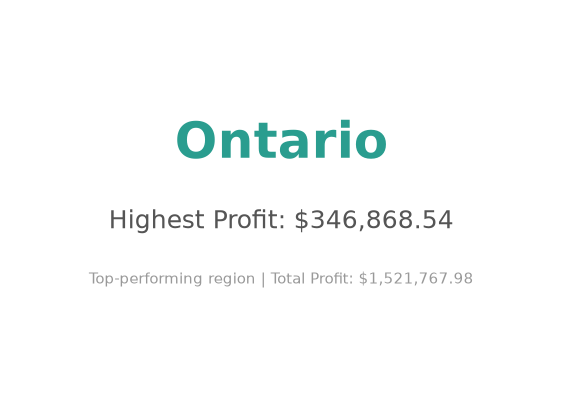

In [4]:
import matplotlib.pyplot as plt

region_totals = sales.groupby("Region")["Profit"].sum().sort_values()
best_region = region_totals.idxmax()
best_profit = region_totals.max()
total_profit = region_totals.sum()

fig, ax = plt.subplots(figsize=(7, 5))
ax.axis("off")

# TODO 1: primary element -- large, bold, colored
ax.text(
    0.5, 0.65,
    best_region,
    fontsize=36,
    fontweight="bold",
    color="#2a9d8f",
    ha="center",
    va="center",
    transform=ax.transAxes
)

# TODO 2: secondary element -- medium, muted color
ax.text(
    0.5, 0.45,
    f"Highest Profit: ${best_profit:,.2f}",
    fontsize=18,
    color="#555555",
    ha="center",
    va="center",
    transform=ax.transAxes
)

# TODO 3: tertiary element -- small, light gray
ax.text(
    0.5, 0.30,
    f"Top-performing region | Total Profit: ${total_profit:,.2f}",
    fontsize=11,
    color="#999999",
    ha="center",
    va="center",
    transform=ax.transAxes
)

plt.show()

**Reflection:** Without reading any labels, in what order do your eyes land on the
three text elements? If someone glanced at this for only 2 seconds, what's the one
fact they'd walk away with?

_Your answer:_My eyes land on the region name first because it's the largest, boldest, and most saturated element on the page — size and weight do the heavy lifting before I even register it as text. From there I drop down to the supporting sentence, which is smaller and in a muted gray-blue, and only last do I notice the light-gray footnote, which barely registers unless I go looking for it. In a 2-second glance, the one fact someone would walk away with is simply "Ontario is the top-performing region" — the hierarchy makes sure that headline survives even if nothing else does.

## Task 2 — Make the Chart Accessible (Complaint #2)

**Real-world usage:** A colorblind or grayscale-printer viewer needs to be able to read
this chart too.

**Why this technique:** Redundant coding (color + pattern/shape) survives both
colorblindness and grayscale printing; color alone does not.

**TODO:**
1. Build a bar chart of total `Sales` by `Product Category`, one color per category.
2. Add a DIFFERENT hatch pattern per bar (`hatch="//"`, `"xx"`, `".."`) on top of the
   color, so the categories stay distinguishable if color is stripped away.
3. Add a legend showing category name.

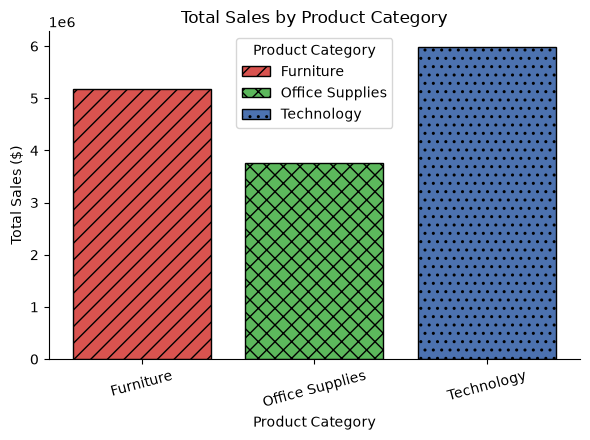

In [5]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

cat_sales = sales.groupby("Product Category")["Sales"].sum()

# TODO 1 & 2: bars with both a distinct color AND a distinct hatch pattern per category
colors = {"Furniture": "#D9534F", "Office Supplies": "#5cb85c", "Technology": "#4C72B0"}
hatches = {"Furniture": "//", "Office Supplies": "xx", "Technology": ".."}

fig, ax = plt.subplots(figsize=(6, 4.5))

for cat in cat_sales.index:
    ax.bar(
        cat,
        cat_sales[cat],
        color=colors[cat],
        hatch=hatches[cat],
        edgecolor="black",
        label=cat
    )

# TODO 3: legend
legend_handles = [
    Patch(
        facecolor=colors[cat],
        hatch=hatches[cat],
        edgecolor="black",
        label=cat
    )
    for cat in cat_sales.index
]

ax.legend(handles=legend_handles, title="Product Category")

ax.set_ylabel("Total Sales ($)")
ax.set_xlabel("Product Category")
ax.set_title("Total Sales by Product Category")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Reflection:** If you only used color (no hatch pattern), which two accessibility
failure modes from the lecture would this chart hit? Name both.

_Your answer:_ First, it would fail for colorblind viewers (especially red-green colorblindness), since the red Furniture bar and the green Office Supplies bar could look nearly identical to someone with deuteranopia or protanopia, making the categories indistinguishable. Second, it would fail on a grayscale printout — three different hues can easily map to very similar shades of gray, so a manager reading a black-and-white printed copy of the report would have no reliable way to tell the bars apart without a color legend they can't use anyway.

## Task 3 — Catch the Axis Exaggeration (Complaint #3)

**Real-world usage:** A headline chart made a small real change look like a crisis.

**Why this technique:** Comparing the SAME data on a zero-baseline axis vs. a truncated
axis reveals exactly how much an axis choice is doing the "storytelling" instead of the
data.

**TODO:**
1. Compute total `Sales` by `Year`.
2. Compute the real percent change between the two most recent years.
3. Plot BOTH a zero-baseline version and a truncated-axis version, side by side, each
   titled with the real percent change.

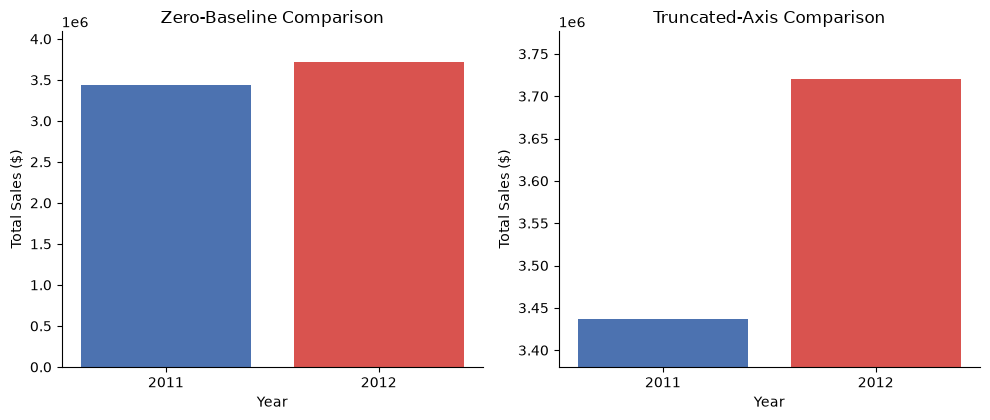

Real change from 2011 to 2012: +8.2%


In [6]:
import numpy as np
import matplotlib.pyplot as plt

yearly_sales = sales.groupby("Year")["Sales"].sum().sort_index()

# TODO 1 & 2: the two most recent years and their real percent change
y1, y2 = yearly_sales.index[-2], yearly_sales.index[-1]
v1, v2 = yearly_sales.loc[y1], yearly_sales.loc[y2]
pct_change = ((v2 - v1) / v1) * 100

fig, axes = plt.subplots(1, 2, figsize=(10, 4.3))

# TODO 3a: zero-baseline version (axes[0])
axes[0].bar(
    [str(y1), str(y2)],
    [v1, v2],
    color=["#4C72B0", "#D9534F"]
)

axes[0].set_ylim(0, max(v1, v2) * 1.1)
axes[0].set_title("Zero-Baseline Comparison")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Total Sales ($)")

# TODO 3b: truncated-axis version (axes[1])
axes[1].bar(
    [str(y1), str(y2)],
    [v1, v2],
    color=["#4C72B0", "#D9534F"]
)

margin = max(abs(v2 - v1) * 0.2, max(abs(v1), abs(v2)) * 0.01)

axes[1].set_ylim(
    min(v1, v2) - margin,
    max(v1, v2) + margin
)

axes[1].set_title("Truncated-Axis Comparison")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Total Sales ($)")

plt.tight_layout()
plt.show()

print(f"Real change from {y1} to {y2}: {pct_change:+.1f}%")

**Reflection:** Which of your two panels would you flag for the manager as
potentially misleading if it were used ALONE as the report's headline chart, with no
other context? Why?

_Your answer:_ I'd flag the truncated-axis panel (the right one). Because its y-axis starts close to the data values instead of at zero, the visual gap between the two bars looks dramatic even though the real change is a modest +8.2%. Used alone as a headline chart, it would make a normal year-over-year fluctuation look like a sharp spike or crisis, which is exactly the kind of exaggeration the manager warned about. The zero-baseline panel on the left shows the same real change with an honest sense of proportion, so it's the safer chart to lead with.

## Task 4 — Rewrite the Overreaching Annotation (Complaint #4)

**Real-world usage:** A colleague's annotation claimed a chart "PROVES" a strategy is
working — language the data alone cannot support.

**Why this technique:** Distinguishing descriptive / interpretive / persuasive
annotation lets you keep useful interpretation while cutting unsupported claims.

**TODO:**
1. Given the overreaching annotation text below, write a DESCRIPTIVE version (states
   only the fact) and an INTERPRETIVE version (explains a plausible, appropriately
   hedged reason) — no causal "PROVES" language in either.
2. Plot the yearly sales trend with your INTERPRETIVE annotation on the most recent
   data point.

ORIGINAL (persuasive, overreaching): This PROVES our new strategy is working -- scale it up immediately
DESCRIPTIVE: Sales increased in the most recent year compared to the previous year.
INTERPRETIVE: The recent sales increase suggests positive performance, but more evidence is needed to determine whether the new strategy caused it.


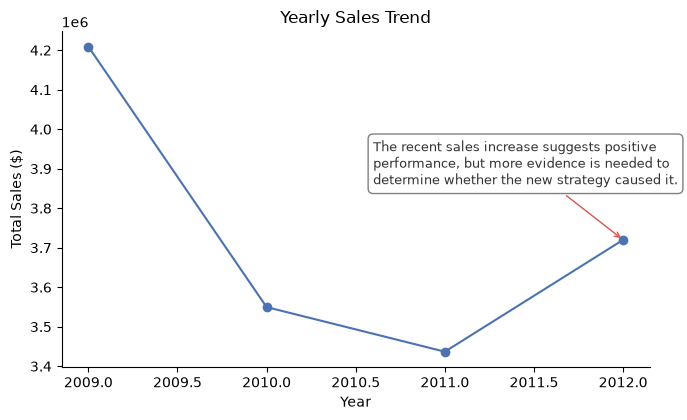

In [7]:
import matplotlib.pyplot as plt

overreaching_original = "This PROVES our new strategy is working -- scale it up immediately"

# TODO 1: your rewrites
descriptive_version = "Sales increased in the most recent year compared to the previous year."

interpretive_version = "The recent sales increase suggests positive performance, but more evidence is needed to determine whether the new strategy caused it."

print("ORIGINAL (persuasive, overreaching):", overreaching_original)
print("DESCRIPTIVE:", descriptive_version)
print("INTERPRETIVE:", interpretive_version)

# TODO 2: plot with your interpretive annotation on the last data point
fig, ax = plt.subplots(figsize=(7, 4.3))

ax.plot(
    yearly_sales.index,
    yearly_sales.values,
    "o-",
    color="#4C72B0"
)

ax.annotate(
    interpretive_version,
    xy=(yearly_sales.index[-1], yearly_sales.values[-1]),
    xytext=(-180, 40),
    textcoords="offset points",
    fontsize=9,
    color="#333333",
    arrowprops=dict(
        arrowstyle="->",
        color="#D9534F"
    ),
    bbox=dict(
        boxstyle="round,pad=0.4",
        facecolor="white",
        edgecolor="gray"
    ),
    wrap=True
)

ax.set_xlabel("Year")
ax.set_ylabel("Total Sales ($)")
ax.set_title("Yearly Sales Trend")

plt.tight_layout()
plt.show()

**Reflection:** What specific evidence would you need (that this dataset alone
doesn't provide) before the ORIGINAL "proves it's working" claim would actually be
justified?

_Your answer:_To actually justify a "proves it's working" claim, I'd need a controlled comparison, not just a before/after trend. That means knowing the exact date the strategy launched, sales data for a comparable control group (a region or segment that didn't get the new strategy) over the same period, and confirmation that other explanations — seasonal patterns, a pricing change, a competitor's move, macroeconomic shifts — have been ruled out. Ideally I'd also want a longer post-launch window than a single year-over-year jump, since one year of data can't separate a real causal effect from ordinary variation.

## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence sign-off note to your manager summarizing
this review. Your answer should:
- State which ONE of the four fixes above you consider the most urgent to ship before
  tomorrow, and why.
- Reference the lecture's 5-question Ethical Visualization Audit — pick one question
  from it and explain how it applies to Task 3 or Task 4 specifically.
- Name one guardrail (a review step, a style-guide rule, etc.) you'd recommend
  permanently adding to the team's process to prevent these four issues recurring.

_Your final recommendation here:_Hi [Manager], here's the sign-off on tomorrow's regional report. Of the four issues, I'd treat the truncated-axis chart in Task 3 as the most urgent to fix before it ships, because it's the one that actively distorts what happened rather than just being unclear or unpolished — a reader could walk away thinking sales are in trouble when the real change is a healthy +8.2%. That ties directly to one question from the lecture's Ethical Visualization Audit: "Does the axis/scale choice accurately represent the magnitude of change?" — which Task 3 fails on the truncated panel and Task 4's annotation almost fails too, since "PROVES it's working" overstates what a single year-over-year trend can support. The hierarchy and accessibility fixes (Tasks 1 and 2) matter for clarity, but they don't risk misleading anyone the way the axis and the causal language do. Going forward, I'd recommend we add a mandatory pre-publish checklist item requiring every chart with a truncated or non-zero axis to be flagged and justified in writing, and every annotation to be labeled as descriptive, interpretive, or persuasive before it can go out. That one rule would have caught three of the four complaints on this draft.